<div dir="rtl">

# סימולציה של מערכת תורים עם פיצול ומיזוג

### במחברת הזאת נבנה סימולציית SimPy למערכת עם ארבע תחנות: $S_1$ מפצלת לקוחות אל $S_2$ ואל $S_3$, ולאחר מכן שתי התחנות מתמזגות אל $S_4$.
### המטרה היא לראות איך מסמנים את מבנה המערכת, איך מגרילים מראש את כל זמני ההגעה והשירות, ואיך מחשבים מתוך הסימולציה התפלגות אורך תור וזמני המתנה בכל תחנה.
### כל פונקציות הסימולציה, ההגרלה והציור נמצאות ב-`utils`. במחברת רק קוראים להן ומציגים את התוצאות.

</div>


In [1]:
import sys
import importlib

sys.path.append("../../code")

import utils
importlib.reload(utils)

from utils import (
    draw_queue_network,
    feed_forward_input_summary,
    network_warmup_summary,
    plot_network_input_densities,
    plot_network_queue_length_distributions,
    plot_network_waiting_time_histograms,
    queue_length_distributions_to_dataframe,
    run_feed_forward_4_station_simpy_example,
)


<div dir="rtl">

## מבנה המערכת

### הלקוחות מגיעים מבחוץ אל $S_1$.
### לאחר סיום השירות ב-$S_1$, כל לקוח נשלח או אל $S_2$ או אל $S_3$.
### לאחר סיום השירות ב-$S_2$ או ב-$S_3$, הלקוח עובר אל $S_4$.
### לאחר סיום השירות ב-$S_4$, הלקוח עוזב את המערכת.

</div>


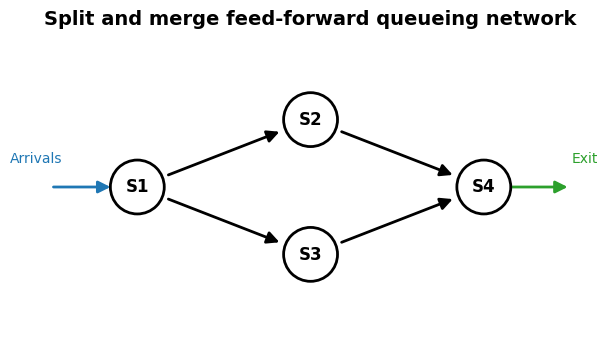

In [2]:
feed_forward_4_positions = {
    "S1": (0, 0),
    "S2": (1.8, 0.7),
    "S3": (1.8, -0.7),
    "S4": (3.6, 0),
}

feed_forward_4_edges = [
    ("S1", "S2"),
    ("S1", "S3"),
    ("S2", "S4"),
    ("S3", "S4"),
]

draw_queue_network(
    positions=feed_forward_4_positions,
    edges=feed_forward_4_edges,
    title="Split and merge feed-forward queueing network",
    entry_nodes=["S1"],
    exit_nodes=["S4"],
)


<div dir="rtl">

## פיצול ומיזוג של תהליכי הגעה

### לפני שמריצים סימולציה, חשוב להבין מה קורה לתהליכי ההגעה בתוך רשת תורים.
### עד עכשיו הרבה פעמים הסתכלנו על תור יחיד, שבו תהליך ההגעה מגיע מבחוץ.
### ברשת תורים המצב שונה: תהליך העזיבה מתחנה אחת הופך לתהליך ההגעה לתחנה אחרת.
### לכן גם אם תהליך ההגעה החיצוני פשוט יחסית, תהליכי ההגעה הפנימיים יכולים להיות מורכבים.

</div>


<div dir="rtl">

## מיזוג תהליכים

### נניח שיש כמה תהליכי הגעה, למשל $N_1(t),N_2(t),...,N_k(t)$, וכולם מגיעים לאותה תחנה.
### תהליך ההגעה הממוזג הוא $N(t)=N_1(t)+N_2(t)+...+N_k(t)$.
### במקרה מיוחד וחשוב, אם כל התהליכים הם תהליכי פואסון בלתי תלויים עם קצבים $\lambda_1,\lambda_2,...,\lambda_k$, אז התהליך הממוזג הוא גם פואסון עם קצב $\lambda=\lambda_1+\lambda_2+...+\lambda_k$.
### זה מקרה יפה, אבל הוא מיוחד מאוד.
### ברשת תורים כללית, תהליכי העזיבה מהתחנות אינם בהכרח פואסון, ובדרך כלל הם גם אינם בלתי תלויים.
### לכן אחרי מיזוג, קשה מאוד למצוא ביטוי מתמטי פשוט לתהליך ההגעה החדש.

</div>


<div dir="rtl">

## פיצול תהליכים

### בפיצול, לקוחות שמסיימים בתחנה מסוימת נשלחים לאחת מכמה תחנות אפשריות.
### כלל הפיצול יכול להיות הסתברותי פשוט: למשל כל לקוח הולך ל-$S_2$ בהסתברות $p$ ול-$S_3$ בהסתברות $1-p$.
### במקרה מיוחד, אם התהליך המקורי הוא פואסון והבחירה לכל לקוח היא בלתי תלויה, אז מקבלים thinning: התהליכים המפוצלים הם פואסון עם קצבים $p\lambda$ ו-$(1-p)\lambda$.
### אבל גם כאן זהו מקרה מיוחד.
### כלל הפיצול יכול להיות תלוי במצב המערכת, למשל לשלוח את הלקוח לתור הקצר ביותר, לתחנה פנויה, או לתחנה עם עדיפות גבוהה.
### ברגע שהניתוב תלוי במצב התורים, תהליך ההגעה לכל תחנה תלוי בדינמיקה של כל הרשת.

</div>


<div dir="rtl">

## למה סימולציה עוזרת כאן

### בדוגמה שלנו $S_1$ מפצלת לקוחות אל $S_2$ ואל $S_3$.
### לאחר מכן $S_2$ ו-$S_3$ מתמזגות אל $S_4$.
### גם אם זמני ההגעה החיצוניים אל $S_1$ הוגרלו מתהליך מוגדר היטב, ההגעה אל $S_4$ היא כבר תוצאה של שני תהליכי עזיבה פנימיים.
### במקום לנסות לגזור נוסחה סגורה לתהליך ההגעה אל $S_4$, הסימולציה מריצה את המערכת עצמה ומודדת את מה שמעניין אותנו: זמני המתנה ואורכי תור.
### זו בדיוק הסיבה שבמערכות תורים עם פיצול, מיזוג וניתוב, סימולציה היא כלי טבעי וחזק.

</div>


<div dir="rtl">

## קלט הסימולציה

### הקלט לסימולציה אינו התפלגויות בלבד, אלא מימושים שכבר הוגרלו מראש.
### אנחנו מגרילים מראש את זמני הביניים בין הגעות אל $S_1$, ואת זמני השירות בכל אחת מהתחנות $S_1,S_2,S_3,S_4$.
### כל זמני ההגעה והשירות מגיעים מהתפלגות Hyper-Erlang עם $10$ ענפים.
### בנוסף מגדירים מטריצת מעבר. בשורות יש את התחנה שממנה הלקוח יצא, ובעמודות יש את התחנה הבאה או יציאה מהמערכת.
### בדוגמה הזאת $P(S_1 \to S_2)=0.55$, $P(S_1 \to S_3)=0.45$, $P(S_2 \to S_4)=1$, $P(S_3 \to S_4)=1$, ו-$P(S_4 \to EXIT)=1$.

</div>


In [3]:
input_data, result = run_feed_forward_4_station_simpy_example(
    num_customers=30_000,
    seed=2026,
    arrival_rate=0.8,
    split_probability_to_s2=0.55,
    warmup_fraction=0.1,
)


<div dir="rtl">

## מטריצת המעבר

### סכום כל שורה במטריצה הוא $1$.
### הסתברות היציאה מהמערכת היא $0$ בכל התחנות פרט ל-$S_4$, ושם הסתברות היציאה היא $1$.

</div>


In [4]:
input_data["routing_matrix"]


,S1,S2,S3,S4,EXIT
S1,0.0,0.55,0.45,0.0,0.0
S2,0.0,0.00,0.00,1.0,0.0
S3,0.0,0.00,0.00,1.0,0.0
S4,0.0,0.00,0.00,0.0,1.0


<div dir="rtl">

## בדיקת יציבות

### כדי שהמערכת תהיה יציבה, העומס בכל תחנה צריך להיות קטן מ-$1$.
### עבור תחנה עם שרת יחיד, העומס הוא בקירוב $\rho_i=\lambda_i E[S_i]$.
### הטבלה הבאה מציגה את קצב ההגעה הצפוי לכל תחנה, זמן השירות הממוצע, והעומס הצפוי.

</div>


In [5]:
feed_forward_input_summary(input_data)


,station,expected_arrival_rate,mean_service_time,utilization
0,S1,0.80,0.75,0.600
1,S2,0.44,0.80,0.352
2,S3,0.36,0.90,0.324
3,S4,0.80,0.70,0.560


<div dir="rtl">

## צפיפות זמני ההגעה והשירות

### הגרף הבא מציג עבור כל קלט גם היסטוגרמה של המימושים וגם את צפיפות ה-Hyper-Erlang התאורטית.
### שימו לב: הסימולציה עצמה מקבלת את המימושים, ולא דוגמת מחדש מתוך ההתפלגות בזמן הריצה.

</div>


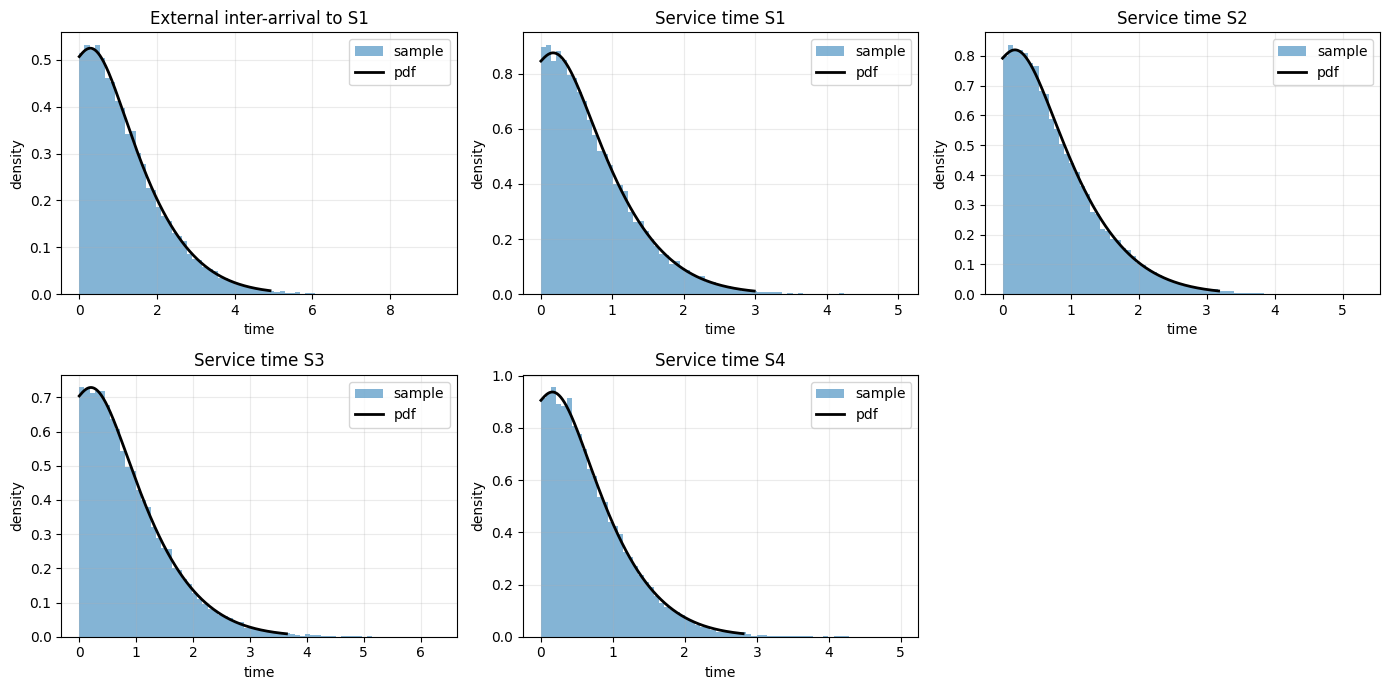

In [6]:
plot_network_input_densities(input_data)


<div dir="rtl">

## Warmup

### בתחילת הסימולציה המערכת ריקה, ולכן המדידות הראשונות בדרך כלל אינן מייצגות מצב סטציונרי.
### במחברת הזאת לא מנסים לאמוד את ה-warmup מתוך הנתונים.
### במקום זאת, מקבלים מראש פרופורציית warmup מתוך אופק הסימולציה.
###     במקרה זה אנחנו משמיטים את $10\%$ הראשונים מזמן הסימולציה.
### אם אופק הסימולציה הוא $T$, אז זמן ה-warmup הוא $T_w=0.1T$.
### לאחר מכן כל זמני ההמתנה והתפלגויות אורך התור מחושבים רק עבור הזמן שאחרי $T_w$.

</div>


<div dir="rtl">

## זמני המתנה לאחר השמטת ה-warmup

### הטבלה הבאה מסכמת את זמני ההמתנה ואת אורך התור הממוצע בכל תחנה לאחר תקופת ה-warmup.
### `mean_waiting_time` הוא זמן ההמתנה הממוצע בתור לפני תחילת שירות.
### `p_wait_positive` הוא שיעור הביקורים שבהם הלקוח באמת המתין.
### `mean_queue_length` מחושב כהתפלגות משוקללת בזמן של אורך התור.

</div>


In [8]:
result["summary"]


,station,num_visits_after_warmup,mean_waiting_time,p_wait_positive,mean_queue_length,p_queue_empty,max_queue_length_observed
0,S1,27016,0.736377,0.537755,0.590133,0.698139,10
1,S2,14769,0.269978,0.303947,0.118279,0.908451,6
2,S3,12248,0.285119,0.285598,0.103591,0.919364,7
3,S4,27018,0.583529,0.508957,0.467695,0.733984,11


<div dir="rtl">

## התפלגות אורך התור

### התפלגות אורך התור היא התפלגות משוקללת בזמן.
### לדוגמה, אם בתחנה מסוימת הערך עבור אורך תור $2$ הוא $0.15$, פירושו שב-$15\%$ מהזמן, אחרי ה-warmup, היו שני לקוחות ממתינים בתור בתחנה הזאת.

</div>


In [9]:
queue_length_distributions_to_dataframe(result).head(25)


,station,queue_length,time_fraction
0,S1,0,0.698139
1,S1,1,0.153426
2,S1,2,0.075843
3,S1,3,0.036178
4,S1,4,0.018671
5,S1,5,0.009710
6,S1,6,0.004669
7,S1,7,0.002153
8,S1,8,0.000801
9,S1,9,0.000332


<div dir="rtl">

## גרפי התוצאות

### כעת נציג את התפלגות זמני ההמתנה בכל תחנה ואת התפלגות אורך התור בכל תחנה.
### ההמתנות מוצגות כהיסטוגרמות, ואורכי התור מוצגים כהסתברויות משוקללות בזמן.

</div>


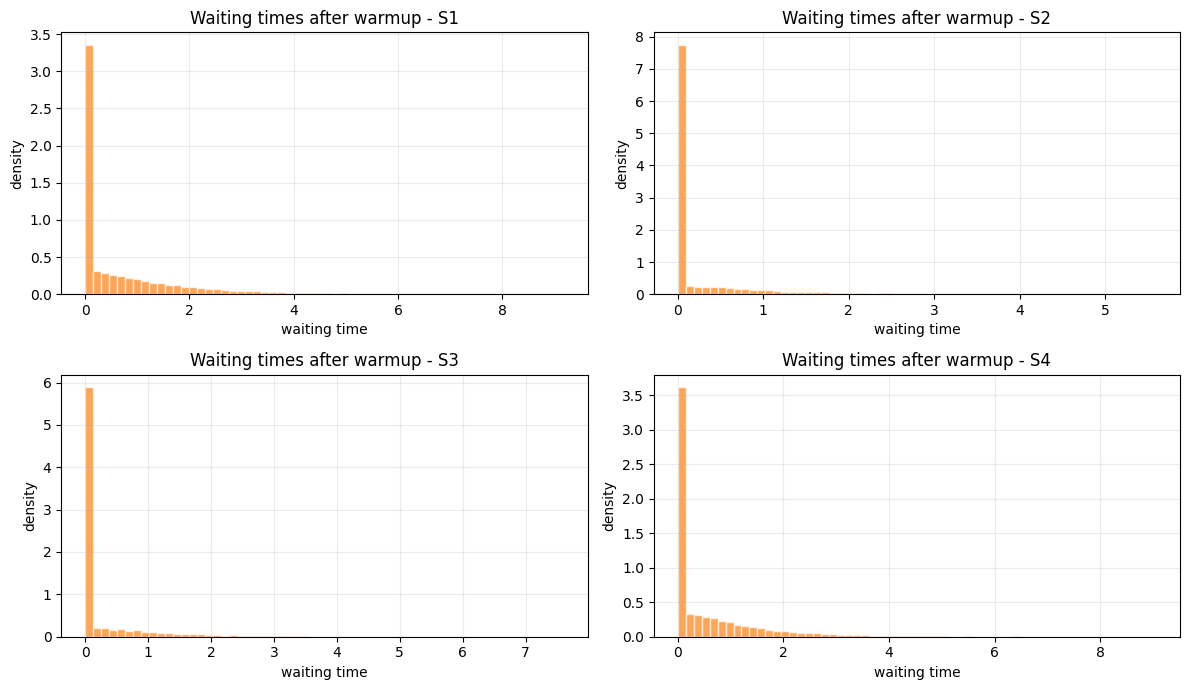

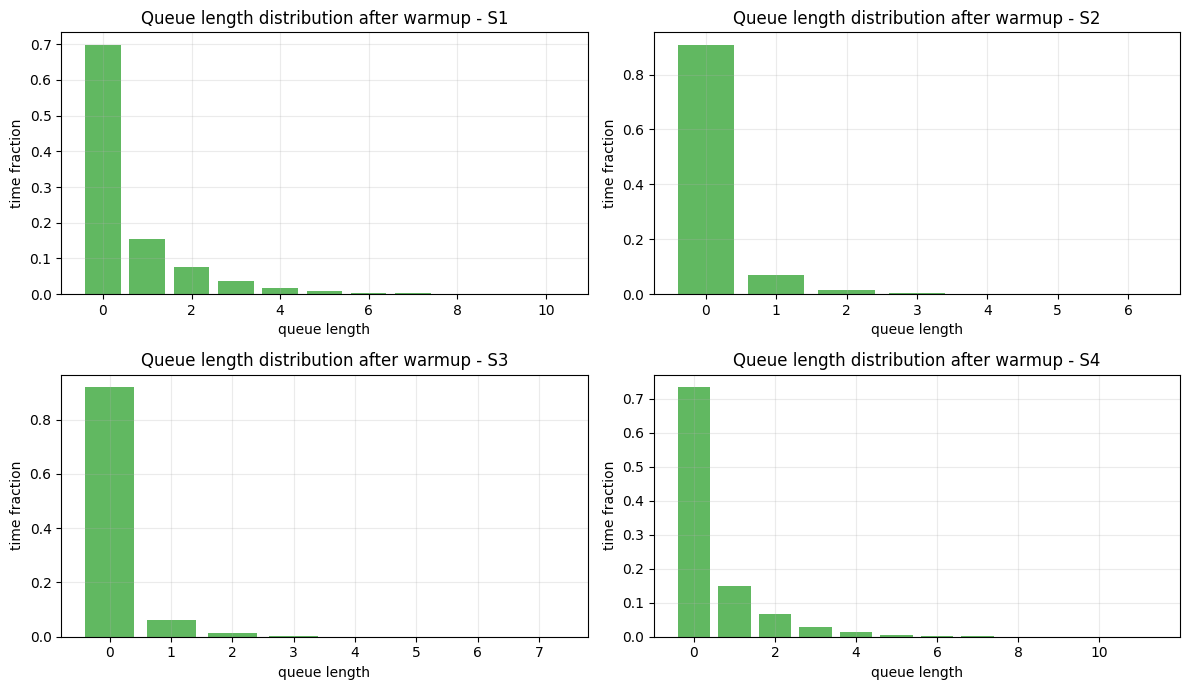

In [10]:
plot_network_waiting_time_histograms(result)
plot_network_queue_length_distributions(result)


<div dir="rtl">

## מה למדנו מהדוגמה

### גם במערכת קטנה יחסית, תהליך ההגעה לתחנות הפנימיות כבר אינו תהליך חיצוני פשוט.
### ההגעה אל $S_4$ היא תוצאה של שני תהליכי עזיבה שמתמזגים: העזיבות מ-$S_2$ והעזיבות מ-$S_3$.
### לכן סימולציה מאפשרת לנו לעבוד ישירות עם מימושי הגעה, שירות וניתוב, בלי לנסות למצוא ביטוי סגור לכל תהליך פנימי במערכת.

</div>
